# Paper 20: Concentration and sector lid

Put a sector cap and a tighter name cap on the IT-heavy FCF book. v2 baseline has no sector cap and a 10% name cap.

Scored against **v2 baseline**. Kill rules are frozen in `Research/book-construction-status.md`:

- Train 2022 calendar more than 5pp worse than SPUS
- Train max drawdown worse than SPUS
- Train Calmar below both v2 baseline and SPUS
- Test 2023 calendar more than 15pp worse than v2 baseline

**Variants.** sector-40, sector-50, name-8, sector-40-name-8.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "monterey" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError(f"Monterey repo root not found from {start}")

_ROOT = _repo_root()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))
try:
    import monterey  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", f"{_ROOT}[research]"])

from monterey.research import boot, compare, run_book
from monterey.sprints import score_against_baseline
from monterey.spec import BookSpec

rd = boot("paper-20-concentration", start="2019-12-01", end="2026-09-30")
print("snapshot", rd.manifest.get("hash"))
print("v2 hash", BookSpec.load("fcf-sma-v2-baseline").hash())

base = run_book("fcf-sma-v2-baseline", rd, paper="20-concentration", id="v2",)

[monterey.data] Loading snapshot ebbbefb35545
        field                   value
       window 2019-12-01 → 2026-09-30
     universe    sp500, point-in-time
      symbols                     631
    snapshots                      85
   price rows                 1147266
    dividends                    9754
filing events                   61274
   halalquant                   0.4.0
snapshot hash            ebbbefb35545
snapshot ebbbefb35545
v2 hash 6ca86844209e


In [2]:
sector_40 = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="20-concentration",
    id="sector-40",
    construction={"sector_cap": 0.40},
)
sector_50 = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="20-concentration",
    id="sector-50",
    construction={"sector_cap": 0.50},
)
name_8 = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="20-concentration",
    id="name-8",
    construction={"name_cap": 0.08},
)
both = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="20-concentration",
    id="sector-40-name-8",
    construction={"sector_cap": 0.40, "name_cap": 0.08},
)

In [3]:
trials = [sector_40, sector_50, name_8, both]
compare([base, *trials], rd)

,total_return,cagr,volatility,max_drawdown,calmar,sharpe,sortino,turnover,costs_pct,dividends_pct,avg_exposure,switches,hash
book,,,,,,,,,,,,,
v2,1.0644,0.1137,0.1463,-0.2482,0.4582,0.6752,0.8589,4.1653,0.0561,0.0561,0.8032,36.0000,6ca86844209e
sector-40,0.9561,0.1048,0.1403,-0.2475,0.4236,0.6406,0.8103,4.2227,0.0568,0.0586,0.8032,36.0000,147feb07242d
sector-50,1.0176,0.1099,0.1442,-0.2482,0.4429,0.6590,0.8350,4.1820,0.0563,0.0569,0.8032,36.0000,37ba1d34a860
name-8,0.9842,0.1072,0.1427,-0.2523,0.4249,0.6472,0.8217,4.2471,0.0572,0.0593,0.8032,36.0000,dd28de1d71d8
sector-40-name-8,0.8815,0.0985,0.1371,-0.2523,0.3904,0.6101,0.7690,4.2908,0.0578,0.0618,0.8032,36.0000,d0a51ac542c5
SPUS (total return),2.1167,0.1840,0.2116,-0.3080,0.5975,0.8123,1.0828,NaN,NaN,NaN,NaN,NaN,NaN
SPY (total return),1.6113,0.1533,0.2006,-0.3372,0.4547,0.7140,0.8854,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
for trial in trials:
    verdict = score_against_baseline(trial, base, rd)
    reasons = "; ".join(verdict["reasons"]) or "pass"
    print(trial.spec.id, "KILLED" if verdict["killed"] else "keep", reasons)

sector-40 keep pass
sector-50 keep pass
name-8 KILLED train Calmar below both v2 baseline and SPUS
sector-40-name-8 KILLED train Calmar below both v2 baseline and SPUS


Kill rules decide keep vs killed. They do not show *how* the books made or lost money.

The book has no "revenue" line. What you plot is **NAV** (wealth of $1) and **drawdown**. For this paper, also plot **IT invested weight** — that is the lid you are testing.

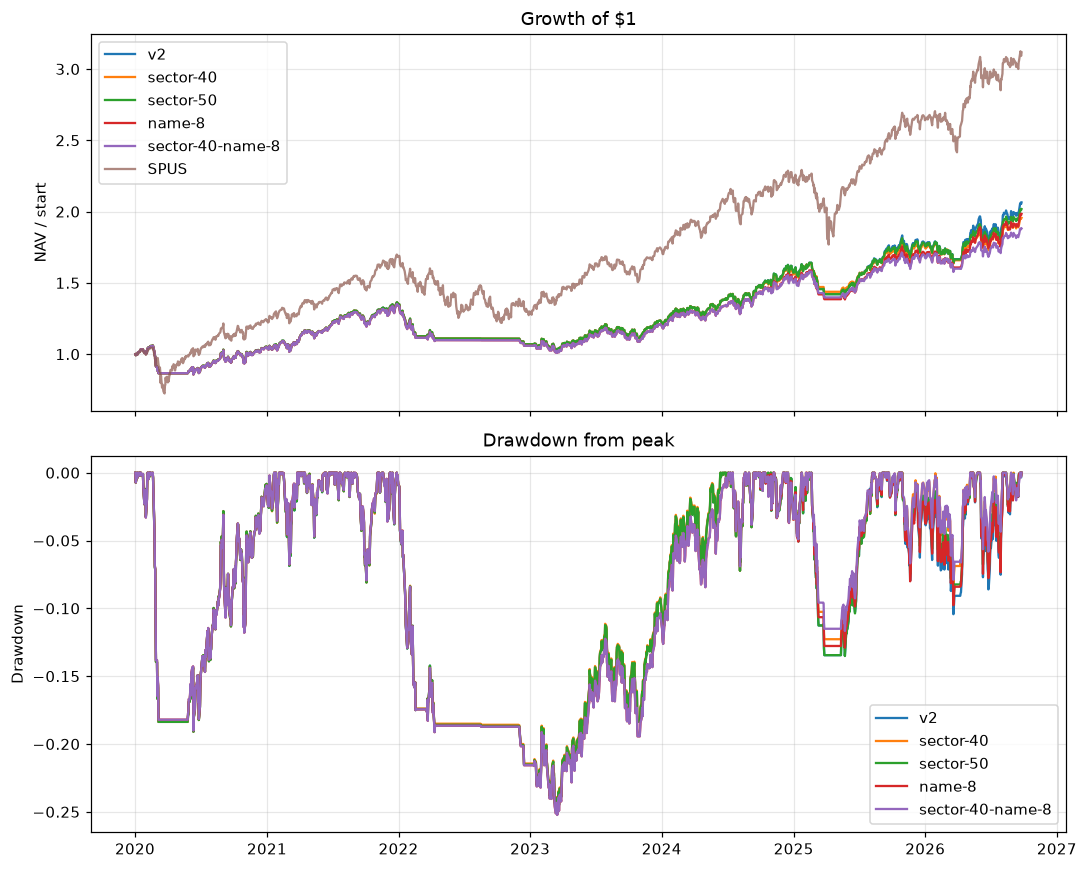

wrote figures/nav-and-drawdown.png


In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from monterey.diagnostics import yearly

books = [base, *trials]
figures = Path("figures")
figures.mkdir(exist_ok=True)

spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for book in books:
    nav = book.nav_series()
    growth = nav / nav.iloc[0]
    axes[0].plot(growth.index, growth, label=book.spec.id)
    dd = nav / nav.cummax() - 1.0
    axes[1].plot(dd.index, dd, label=book.spec.id)

axes[0].plot(spus.index, spus / spus.iloc[0], label="SPUS", alpha=0.7)
axes[0].set_title("Growth of $1")
axes[0].set_ylabel("NAV / start")
axes[0].legend()
axes[1].set_title("Drawdown from peak")
axes[1].set_ylabel("Drawdown")
axes[1].legend()

fig.tight_layout()
fig.savefig(figures / "nav-and-drawdown.png", dpi=140)
plt.show()
print("wrote", figures / "nav-and-drawdown.png")

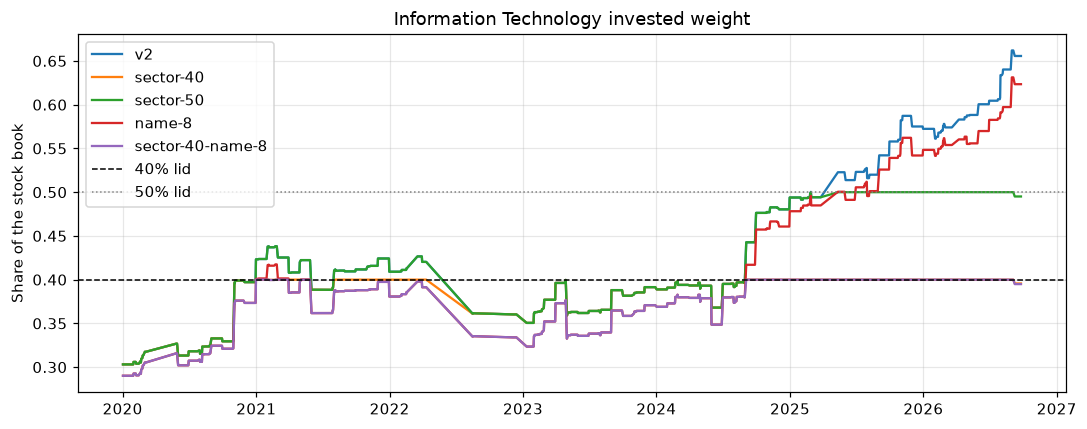

wrote figures/it-weight.png


In [6]:
def invested_it_weight(ledger) -> pd.Series:
    pos = ledger.positions.copy()
    pos["date"] = pd.to_datetime(pos["date"])
    pos["invested_weight"] = pos["invested_weight"].astype(float)
    live = pos[pos["invested_weight"] > 0]
    if live.empty:
        return pd.Series(dtype=float)
    tot = live.groupby("date")["invested_weight"].sum()
    it = live[live["sector"].fillna("").str.lower().str.contains("information technology")]
    return it.groupby("date")["invested_weight"].sum().reindex(tot.index).fillna(0.0) / tot

fig, ax = plt.subplots(figsize=(10, 4))
for book in books:
    series = invested_it_weight(book)
    ax.plot(series.index, series, label=book.spec.id)
ax.axhline(0.40, color="black", ls="--", lw=1, label="40% lid")
ax.axhline(0.50, color="gray", ls=":", lw=1, label="50% lid")
ax.set_title("Information Technology invested weight")
ax.set_ylabel("Share of the stock book")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "it-weight.png", dpi=140)
plt.show()
print("wrote", figures / "it-weight.png")

,v2,sector-40,sector-50,name-8,sector-40-name-8,SPUS
year,,,,,,
2020,0.0528,0.0528,0.0528,0.0496,0.0496,0.2399
2021,0.2831,0.2830,0.2831,0.2759,0.2759,0.3562
2022,-0.2080,-0.2076,-0.2080,-0.2090,-0.2090,-0.2276
2023,0.1525,0.1525,0.1525,0.1395,0.1394,0.3420
2024,0.2741,0.2636,0.2741,0.2528,0.2438,0.2649
2025,0.1250,0.1209,0.1209,0.1210,0.1176,0.1978
2026,0.1681,0.1196,0.1458,0.1706,0.1214,0.1802


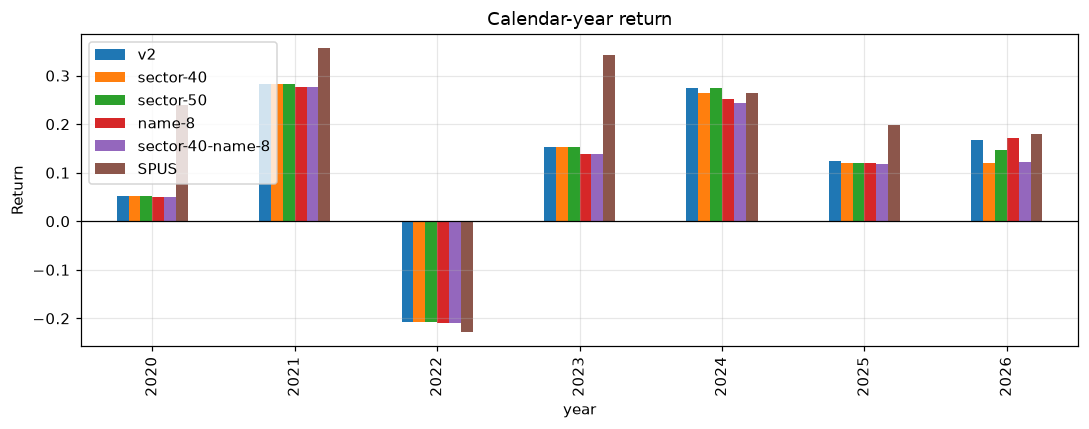

wrote figures/calendar-returns.png


In [7]:
calendar = pd.concat(
    {book.spec.id: yearly(book.nav_series())["return"] for book in books},
    axis=1,
)
calendar["SPUS"] = yearly(spus)["return"]
display(calendar)

ax = calendar.plot(kind="bar", figsize=(10, 4))
ax.set_title("Calendar-year return")
ax.set_ylabel("Return")
ax.axhline(0, color="black", lw=0.8)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figures / "calendar-returns.png", dpi=140)
plt.show()
print("wrote", figures / "calendar-returns.png")